
# Pipeline de modelos — Clasificación multietiqueta en Esperanto

**Asignatura:** Minería de Textos  
**Curso:** 2026–2027

## Objetivo

Este notebook desarrolla la tercera fase del proyecto: el entrenamiento, evaluación y aplicación de modelos de clasificación temática sobre textos en Esperanto.

Utilizamos el dataset generado y procesado en `pipeline_datos.ipynb`.

Se comparan dos modelos:

1. **TF-IDF + LinearSVC:** clasificador lineal utilizando un enfoque One-vs-Rest.
2. **TF-IDF + MLP:** red neuronal multicapa entrenada desde cero.

Ambos modelos permiten asignar simultáneamente varias categorías a cada párrafo:

- Ciberseguridad
- Inteligencia Artificial
- Programación

La comparación se realiza mediante validación cruzada agrupada por URL, utilizando F1 macro como criterio principal.

Finalmente, se evalúan los modelos sobre artículos reservados para prueba y se aplica el clasificador seleccionado a páginas web en Esperanto.


In [1]:
import sys
import os
import requests
from pathlib import Path

ruta = Path("/content/Entrega_Final_Mineria")

if not ruta.exists():
    !git clone https://github.com/Hernanfd/Entrega_Final_Mineria.git /content/Entrega_Final_Mineria

os.chdir(ruta)
%pip install -e .
sys.path.insert(0, str(ruta / "src"))

Obtaining file:///C:/content/Entrega_Final_Mineria
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for esperanto-nlp-equipo (pyproject.toml): started
  Building editable for esperanto-nlp-equipo (pyproject.toml): finished with status 'done'
  Created wheel for esperanto-nlp-equipo: filename=esperanto_nlp_equipo-0.1.0-0.editable-py3-none-any.whl size=4227 sha256=1ed569fd2154dab3feb71469f822e862b1bfe818ae47ed1ce38a9ef5b94b2925
  Stored in directory: C:\Users\Hernán\AppData\Local\Temp\pip-ephem-wheel-cache-9t9zke7z\wheels\8b\92\5


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer

from esperanto_nlp.modelo import (
    ETIQUETAS,
    matriz_etiquetas,
    cargar_datos_modelo,
    separar_datos,
    comparar_modelos,
    evaluar_modelos,
    exportar_errores,
    guardar_modelos,
)

from esperanto_nlp.main import clasificar_pagina

RUTA_DATOS = Path(
    "data/procesados/dataset_multietiqueta_procesado.csv"
)

print("Librerías importadas correctamente.")
print("Dataset procesado disponible:", RUTA_DATOS.is_file())

from esperanto_nlp.procesar_dataset import procesar_dataset

if not RUTA_DATOS.is_file():
    procesar_dataset()

print("Dataset procesado disponible:", RUTA_DATOS.is_file())

Librerías importadas correctamente.
Dataset procesado disponible: True
Dataset procesado disponible: True



## 1. Preparación de los datos

El dataset procesado contiene los textos normalizados mediante nuestra librería EsperantoNLP y las tres etiquetas binarias correspondientes a las categorías temáticas.

Para el experimento inicial se utilizan los registros con anotaciones completas y estado `propuesto`.

Los registros pendientes de revisión y aquellos sin categoría se conservan en el dataset original, pero no intervienen en este entrenamiento.

### Separación de entrenamiento y prueba

La partición se realiza agrupando los párrafos por URL, de forma que todos los párrafos pertenecientes a un mismo artículo permanezcan en el mismo conjunto.

Esta decisión reduce el riesgo de fuga de información entre entrenamiento y prueba, ya que los párrafos de un mismo artículo pueden compartir terminología y contexto.

Las anotaciones utilizadas son propuestas asistidas, por lo que los resultados de evaluación deben considerarse preliminares hasta disponer de etiquetas verificadas.


In [3]:
# Cargar el dataset multietiqueta procesado
datos = cargar_datos_modelo()

# Separar entrenamiento y prueba por URL
entrenamiento, prueba = separar_datos(datos)

# Preparar textos
textos_train = [fila["text"] for fila in entrenamiento]
textos_test = [fila["text"] for fila in prueba]

# Preparar etiquetas multietiqueta
y_train = matriz_etiquetas(entrenamiento)
y_test = matriz_etiquetas(prueba)

print("\nDimensiones de los datos:")

print("Textos de entrenamiento:", len(textos_train))
print("Textos de prueba:", len(textos_test))

print("Etiquetas entrenamiento:", y_train.shape)
print("Etiquetas prueba:", y_test.shape)

print("\nOrden de las categorías:")
print(ETIQUETAS)

Filas leídas: 1659
Pendientes: 59
Sin categoría: 22
Propuestas vacías: 0

Datos disponibles
Textos: 1578
URLs: 120
Positivos de Ciberseguridad: 491
Positivos de IA: 618
Positivos de Programacion: 577
Textos con varias etiquetas: 108

Entrenamiento
Textos: 1215
URLs: 96
Positivos de Ciberseguridad: 398
Positivos de IA: 437
Positivos de Programacion: 450
Textos con varias etiquetas: 70

Prueba
Textos: 363
URLs: 24
Positivos de Ciberseguridad: 93
Positivos de IA: 181
Positivos de Programacion: 127
Textos con varias etiquetas: 38

URLs compartidas: 0

Dimensiones de los datos:
Textos de entrenamiento: 1215
Textos de prueba: 363
Etiquetas entrenamiento: (1215, 3)
Etiquetas prueba: (363, 3)

Orden de las categorías:
('Ciberseguridad', 'IA', 'Programacion')



## 2. Vectorización mediante TF-IDF

Los algoritmos de clasificación requieren una representación numérica de los textos.

Utilizamos **TF-IDF (Term Frequency–Inverse Document Frequency)**, que asigna pesos a los términos en función de su presencia en cada párrafo y su distribución en el corpus.

La representación se construye a partir de los textos procesados previamente mediante nuestra librería EsperantoNLP.

El vectorizador utiliza los siguientes parámetros:

- `lowercase=False`: los textos ya se han normalizado.
- `token_pattern=r"(?u)\b\w+\b"`: permite trabajar con tokens de un carácter o más.
- `min_df=2`: excluye términos presentes en menos de dos documentos del conjunto de ajuste.

Para evitar fugas de información, TF-IDF se ajusta únicamente sobre los textos de entrenamiento.

Durante la validación cruzada, cada modelo vuelve a ajustar su propio vectorizador utilizando exclusivamente la parte de entrenamiento de cada partición.


In [4]:
# Demostración de vectorización TF-IDF
vectorizador = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b",
    min_df=2
)

X_train = vectorizador.fit_transform(textos_train)
X_test = vectorizador.transform(textos_test)

print("Matriz TF-IDF de entrenamiento:", X_train.shape)
print("Matriz TF-IDF de prueba:", X_test.shape)

print(
    "Tamaño del vocabulario:",
    len(vectorizador.vocabulary_)
)

# Mostrar algunos términos del vocabulario
terminos = vectorizador.get_feature_names_out()

print("\nPrimeros 20 términos:")
print(terminos[:20])

Matriz TF-IDF de entrenamiento: (1215, 2971)
Matriz TF-IDF de prueba: (363, 2971)
Tamaño del vocabulario: 2971

Primeros 20 términos:
['a' 'aaabbb' 'ab' 'abstrakta' 'abstraktado' 'abundo' 'ack' 'adam'
 'adapta' 'adaptebleco' 'adapti' 'adaptita' 'adaptiĝi' 'adaptiĝo' 'adicio'
 'administrada' 'administrado' 'administranto' 'administrata' 'administri']



## 3. Entrenamiento de modelos

Se entrenan dos clasificadores multietiqueta utilizando la misma representación textual.

### 3.1. LinearSVC

LinearSVC es un clasificador lineal basado en máquinas de vectores de soporte.

Para permitir múltiples etiquetas utilizamos `OneVsRestClassifier`, que entrena un clasificador binario independiente para cada categoría.

### 3.2. Red neuronal MLP

La segunda arquitectura utiliza `MLPClassifier`, una red neuronal multicapa con:

- Una capa oculta de 64 neuronas.
- Función de activación ReLU.
- Optimizador Adam.
- Regularización L2.
- Semilla aleatoria fija para favorecer la reproducibilidad.

La red se entrena desde cero, sin utilizar pesos preentrenados.

### 3.3. Validación cruzada

Se utiliza validación cruzada de tres particiones agrupadas por URL.

Ambos modelos utilizan las mismas particiones. La selección se realiza mediante el F1 macro medio, dando el mismo peso a las tres categorías.

El conjunto de prueba permanece separado durante la selección.


In [5]:
# Entrenar y comparar ambos modelos
modelos, resultados_cv, elegido = comparar_modelos(
    entrenamiento
)

print("\nModelo seleccionado:", elegido)


Validación de LinearSVC
Partición 1/3: F1 macro = 0.9013 | F1 micro = 0.8998
Partición 2/3: F1 macro = 0.8676 | F1 micro = 0.8726
Partición 3/3: F1 macro = 0.8782 | F1 micro = 0.8744

Validación de MLP
Partición 1/3: F1 macro = 0.9007 | F1 micro = 0.8992
Partición 2/3: F1 macro = 0.8713 | F1 micro = 0.8765
Partición 3/3: F1 macro = 0.8942 | F1 micro = 0.8905

COMPARACIÓN EN VALIDACIÓN
LinearSVC: F1 macro = 0.8823 ± 0.0141 | F1 micro = 0.8823 | Coincidencia exacta = 0.8066 | Tiempo = 0.29 s
MLP: F1 macro = 0.8887 ± 0.0126 | F1 micro = 0.8888 | Coincidencia exacta = 0.8181 | Tiempo = 32.07 s

Seleccionado: MLP
Entrenando LinearSVC con todos los datos...
Tiempo: 0.06 s | Aviso de convergencia: False
Entrenando MLP con todos los datos...
Tiempo: 12.69 s | Aviso de convergencia: False

Modelo seleccionado: MLP


Resultados de validación cruzada:


,f1_macro_media,f1_macro_desv,f1_micro_media,coincidencia_exacta_media,segundos_ajuste_cv
LinearSVC,0.8823,0.0141,0.8823,0.8066,0.2903
MLP,0.8887,0.0126,0.8888,0.8181,32.0691


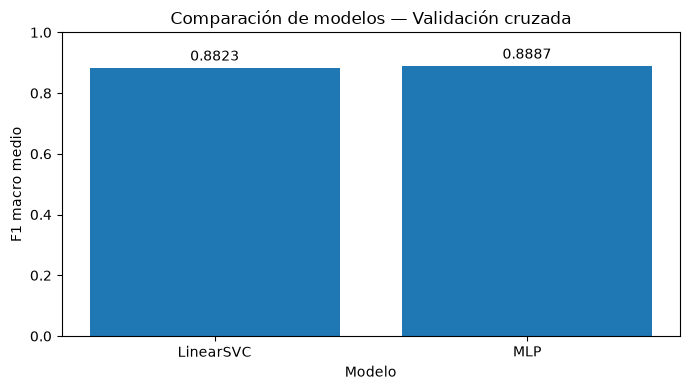

Modelo seleccionado: MLP


In [6]:
# Construir tabla de validación
tabla_cv = pd.DataFrame(resultados_cv).T

columnas_cv = [
    "f1_macro_media",
    "f1_macro_desv",
    "f1_micro_media",
    "coincidencia_exacta_media",
    "segundos_ajuste_cv",
]

print("Resultados de validación cruzada:")
display(tabla_cv[columnas_cv].round(4))

# Visualización del F1 macro
fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    tabla_cv.index,
    tabla_cv["f1_macro_media"]
)

ax.set_title("Comparación de modelos — Validación cruzada")
ax.set_xlabel("Modelo")
ax.set_ylabel("F1 macro medio")
ax.set_ylim(0, 1)

ax.bar_label(barras, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

print("Modelo seleccionado:", elegido)


## 4. Evaluación final de los modelos

Una vez seleccionado el modelo mediante validación cruzada, se evalúan ambas arquitecturas sobre los artículos reservados para prueba.

Se utilizan métricas apropiadas para clasificación multietiqueta:

- **F1 macro:** media del F1 de cada categoría.
- **F1 micro:** F1 calculado agregando las decisiones de todas las etiquetas.
- **F1 por muestra:** rendimiento medio de las etiquetas asignadas a cada párrafo.
- **Coincidencia exacta:** porcentaje de párrafos cuyas etiquetas predichas coinciden completamente con las propuestas.
- **Hamming loss:** proporción de decisiones de etiqueta incorrectas.
- **Jaccard por muestra:** similitud entre los conjuntos de etiquetas propuestas y predichas.

También se muestran precision, recall y F1 por categoría, además de matrices de confusión binarias.

Estos resultados describen el comportamiento de los modelos respecto a las anotaciones disponibles. No constituyen una evaluación definitiva frente a etiquetas humanas completamente verificadas.


In [7]:
# Evaluación sobre los artículos reservados para prueba
resultados_prueba = evaluar_modelos(
    modelos,
    prueba
)

print("\nEvaluación final completada.")


PRUEBA FINAL — LinearSVC
f1_macro: 0.8992
f1_micro: 0.9025
f1_samples: 0.8825
coincidencia_exacta: 0.8237
hamming_loss: 0.0670
jaccard_samples: 0.8678
                precision    recall  f1-score   support

Ciberseguridad     0.9878    0.8710    0.9257        93
            IA     0.9701    0.8950    0.9310       181
  Programacion     0.9596    0.7480    0.8407       127

     micro avg     0.9713    0.8429    0.9025       401
     macro avg     0.9725    0.8380    0.8992       401
  weighted avg     0.9709    0.8429    0.9012       401
   samples avg     0.9077    0.8719    0.8825       401

Matrices de confusión por categoría:
Ciberseguridad
[[269   1]
 [ 12  81]]
IA
[[177   5]
 [ 19 162]]
Programacion
[[232   4]
 [ 32  95]]
Predicciones sin etiqueta: 25

PRUEBA FINAL — MLP
f1_macro: 0.9172
f1_micro: 0.9179
f1_samples: 0.9137
coincidencia_exacta: 0.8457
hamming_loss: 0.0579
jaccard_samples: 0.8967
                precision    recall  f1-score   support

Ciberseguridad     0.9885  

Comparación en el conjunto de prueba:


,f1_macro,f1_micro,f1_samples,coincidencia_exacta,hamming_loss,jaccard_samples
LinearSVC,0.8992,0.9025,0.8825,0.8237,0.0670,0.8678
MLP,0.9172,0.9179,0.9137,0.8457,0.0579,0.8967


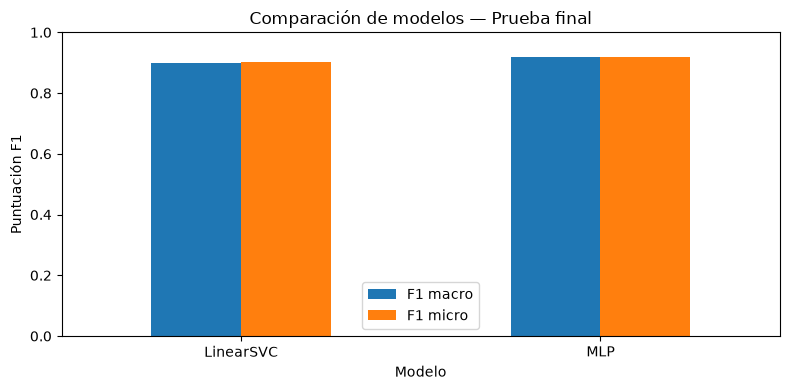

In [8]:
# Seleccionar las métricas principales
metricas = [
    "f1_macro",
    "f1_micro",
    "f1_samples",
    "coincidencia_exacta",
    "hamming_loss",
    "jaccard_samples",
]

tabla_prueba = pd.DataFrame({
    nombre: {
        metrica: resultados[metrica]
        for metrica in metricas
    }
    for nombre, resultados in resultados_prueba.items()
}).T

print("Comparación en el conjunto de prueba:")
display(tabla_prueba.round(4))

# Gráfico de F1 macro y F1 micro
fig, ax = plt.subplots(figsize=(8, 4))

tabla_prueba[
    ["f1_macro", "f1_micro"]
].plot.bar(ax=ax, rot=0)

ax.set_title("Comparación de modelos — Prueba final")
ax.set_xlabel("Modelo")
ax.set_ylabel("Puntuación F1")
ax.set_ylim(0, 1)

ax.legend(["F1 macro", "F1 micro"])

plt.tight_layout()
plt.show()


## 5. Análisis de errores

Además de las métricas agregadas, analizamos las discrepancias entre las etiquetas propuestas y las predicciones.

El análisis permite identificar:

- Párrafos para los que no se predice ninguna categoría.
- Párrafos que reciben etiquetas adicionales.
- Categorías que los clasificadores no identifican.
- Casos donde ambos modelos presentan discrepancias.

Las predicciones se exportan a un CSV para facilitar la inspección de los textos originales.

Una discrepancia con la anotación propuesta no demuestra necesariamente un error semántico del modelo: también puede reflejar ambigüedad o problemas de calidad en las etiquetas.

El conjunto de prueba no se utiliza para ajustar hiperparámetros ni seleccionar el clasificador.


In [9]:
# Exportar predicciones para inspección
exportar_errores(
    modelos,
    prueba
)

# Guardar los pipelines entrenados
guardar_modelos(
    modelos,
    elegido
)

print("\nArchivos generados:")

archivos = [
    Path("data/resultados/analisis_errores.csv"),
    Path("data/modelos/linearsvc.joblib"),
    Path("data/modelos/mlp.joblib"),
    Path("data/modelos/modelo_seleccionado.txt"),
]

for archivo in archivos:
    print(
        f"{archivo}:",
        "OK" if archivo.is_file() else "NO ENCONTRADO"
    )


Análisis guardado en: data\resultados\analisis_errores.csv
Párrafos analizados: 363

LinearSVC
Párrafos con errores: 64
Predicciones sin etiqueta: 25

MLP
Párrafos con errores: 56
Predicciones sin etiqueta: 14

Párrafos incorrectos en ambos modelos: 48
Modelo guardado: data\modelos\linearsvc.joblib
Modelo guardado: data\modelos\mlp.joblib
Modelo seleccionado: MLP

Archivos generados:
data\resultados\analisis_errores.csv: OK
data\modelos\linearsvc.joblib: OK
data\modelos\mlp.joblib: OK
data\modelos\modelo_seleccionado.txt: OK



## 6. Clasificación de páginas web nuevas

Para comprobar el funcionamiento del sistema en un entorno real, utilizamos el modelo seleccionado para clasificar una página web escrita en Esperanto.

El procedimiento realiza las siguientes operaciones:

1. Descarga el contenido de la página.
2. Extrae los párrafos del contenido principal.
3. Aplica nuestra librería EsperantoNLP.
4. Transforma los textos utilizando el TF-IDF del modelo entrenado.
5. Predice las categorías de cada párrafo.
6. Obtiene una puntuación de pertenencia a cada categoría.

La clasificación es multietiqueta, por lo que un párrafo puede recibir simultáneamente IA y Programación, por ejemplo.

Cuando se utiliza la MLP, las puntuaciones se obtienen mediante `predict_proba`. Son estimaciones de pertenencia a cada categoría y no necesariamente probabilidades calibradas.

Para LinearSVC, los valores corresponden a márgenes de decisión, no a probabilidades.

Se utiliza una página de Wikipedia en Esperanto como prueba de funcionamiento con una fuente diferente de la utilizada para construir el corpus principal.


In [10]:
# Página externa de ejemplo
URL_PRUEBA = (
    "https://eo.wikipedia.org/wiki/Artefarita_inteligenteco"
)

# Ejecutar una prueba web
# Cambiar a False si se quiere ejecutar el notebook sin conexión
EJECUTAR_PRUEBA_WEB = True

resultados_web = []

if EJECUTAR_PRUEBA_WEB:
    try:
        resultados_web = clasificar_pagina(
            URL_PRUEBA,
            nombre_modelo=elegido
        )

        print("Modelo utilizado:", elegido)
        print("Párrafos extraídos:", len(resultados_web))

        df_web = pd.DataFrame(resultados_web)

        columnas = [
            "parrafo",
            "categorias",
            "pred_Ciberseguridad",
            "pred_IA",
            "pred_Programacion",
        ]

        print("\nPrimeros 10 párrafos clasificados:")
        display(df_web[columnas].head(10))

    except Exception as error:
        print("No se pudo completar la prueba web.")
        print("Motivo:", error)
        print("El entrenamiento y la evaluación no se ven afectados.")

else:
    print("Prueba web desactivada.")

Modelo utilizado: MLP
Párrafos extraídos: 44

Primeros 10 párrafos clasificados:


,parrafo,categorias,pred_Ciberseguridad,pred_IA,pred_Programacion
0,1,Programacion,0,0,1
1,2,IA,0,1,0
2,3,IA,0,1,0
3,4,IA,0,1,0
4,5,IA,0,1,0
5,6,Sin etiqueta,0,0,0
6,7,IA,0,1,0
7,8,Programacion,0,0,1
8,9,IA,0,1,0
9,10,IA,0,1,0


Distribución de etiquetas en la página:
Ciberseguridad     0
IA                28
Programacion       9
dtype: int64


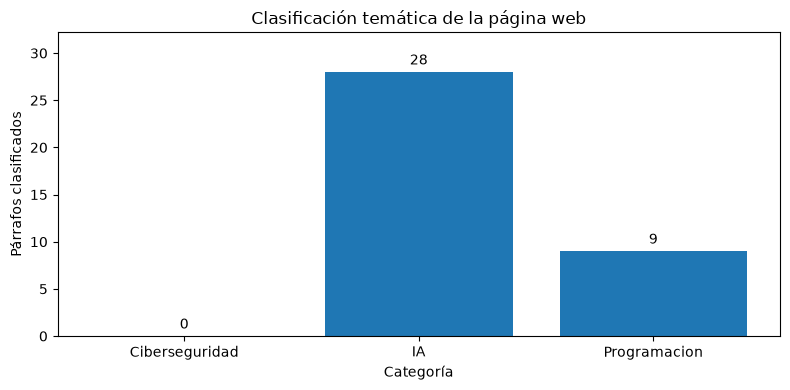


Ejemplos de resultados:


,parrafo,texto_original,categorias
0,1,Malneta versio,Programacion
1,2,"Artefarita intelekto [ 1 ] [ 2 ] ( AI ), kelkf...",IA
2,3,"La jardekojn longa filozofia disputo, ĉu el la...",IA
3,4,La artefaritan intelekton oni fojfoje nomas ma...,IA
4,5,Artefarita intelekto estis fondita kiel scienc...,IA
5,6,"En la 21-a jarcento, AI-teknikoj travivis rene...",Sin etiqueta
6,7,En Julio 1956 ĉe la Kolegio Dartmouth okazis k...,IA
7,8,"Per apogo sur la studoj de Alan Turing , inter...",Programacion
8,9,"La opinion, ke intelekto estas sendependa de l...",IA
9,10,Speciale la komenca fazo de la AI estis regata...,IA


In [11]:
if resultados_web:
    df_web = pd.DataFrame(resultados_web)

    # Conservar únicamente las predicciones válidas
    df_clasificados = df_web[
        df_web["categorias"] != "No clasificable"
    ].copy()

    frecuencias_web = pd.Series({
        categoria: pd.to_numeric(
            df_clasificados[f"pred_{categoria}"],
            errors="coerce"
        ).fillna(0).sum()
        for categoria in ETIQUETAS
    })

    print("Distribución de etiquetas en la página:")
    print(frecuencias_web.astype(int))

    fig, ax = plt.subplots(figsize=(8, 4))

    barras = ax.bar(
        frecuencias_web.index,
        frecuencias_web.values
    )

    ax.set_title("Clasificación temática de la página web")
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Párrafos clasificados")

    ax.bar_label(barras, fmt="%.0f", padding=3)
    ax.set_ylim(0, max(1, frecuencias_web.max() * 1.15))

    plt.tight_layout()
    plt.show()

    print("\nEjemplos de resultados:")
    display(
        df_web[
            ["parrafo", "texto_original", "categorias"]
        ].head(10)
    )

else:
    print("No hay resultados web que representar.")

In [12]:
paginas_prueba = {
    # "Inteligencia Artificial": "https://eo.wikipedia.org/wiki/Artefarita_intelekto",

    # "Python": "https://eo.wikipedia.org/wiki/Python_(programlingvo)",

    # "Criptografía": "https://eo.wikipedia.org/wiki/Kriptografio",

    # "Java": "https://eo.wikipedia.org/wiki/Java_(programlingvo)",

    "JavaScript": "https://eo.wikipedia.org/wiki/JavaScript", #  
}

for nombre, url in paginas_prueba.items():
    print("\n" + "=" * 70)
    print(nombre)
    print("=" * 70)

    try:
        resultados = clasificar_pagina(url, nombre_modelo="MLP")
        tabla = pd.DataFrame(resultados)

        print("Párrafos extraídos:", len(tabla))

        display(tabla[[
            "parrafo",
            "texto_original",
            "categorias",
            "score_Ciberseguridad",
            "score_IA",
            "score_Programacion"
        ]])

    except (requests.RequestException, ValueError) as error:
        print("Error:", error)


JavaScript
Párrafos extraídos: 32


,parrafo,texto_original,categorias,score_Ciberseguridad,score_IA,score_Programacion
0,1,JavaScript (ankaŭ nomata Ĝavoskripto [ 1 ] aŭ ...,Programacion,0.0032,0.0033,0.9981
1,2,Oficiale Ĝavoskripton difinas la normo ECMA‑26...,Sin etiqueta,0.3214,0.0149,0.3699
2,3,Ĝin funkciigas TTT-legiloj . Por sekureco de p...,Programacion,0.0321,0.0075,0.6639
3,4,"Utilo de la lingvo estas, ke dank ĝi TTT-legil...",Sin etiqueta,0.0030,0.4464,0.1639
4,5,Ŝatantoj de Ĝavoskripto ricevis grandan ĝojon ...,Programacion,0.0093,0.0388,0.9432
5,6,Unu el novaj uzoj de Ĝavoskripto estas malreal...,Programacion,0.0429,0.0427,0.7752
6,7,Ekzistas ankaŭe unu malavantaĝo: Poŝtelefona p...,Programacion,0.0051,0.0117,0.9420
7,8,Ekzistas ankaŭ uzoj de Ĝavoskripto ne TTT-legi...,Sin etiqueta,0.0685,0.0133,0.3350
8,9,Ĝavoskripto ne tipigas variablojn. Variablojn ...,Programacion,0.0033,0.0192,0.9661
9,10,"Vi povas vidi, ke, malsimile al Ĝavo, oni ne d...",Programacion,0.0033,0.0030,0.9953



## 7. Conclusiones

Se ha desarrollado un sistema de clasificación temática multietiqueta para textos escritos en Esperanto.

El proceso combina una librería NLP propia basada en reglas, la representación TF-IDF y dos algoritmos de clasificación: LinearSVC y una red neuronal MLP.

La comparación de ambas arquitecturas se realiza mediante validación cruzada agrupada por URL, utilizando F1 macro como criterio de selección.

El sistema permite clasificar párrafos que pertenecen a varias categorías simultáneamente y aplicar los modelos entrenados a nuevas páginas web.

### Limitaciones

- Las etiquetas utilizadas para el entrenamiento y la evaluación proceden de una propuesta de anotación asistida y no están completamente verificadas.
- Algunos párrafos son ambiguos o requieren el contexto del artículo para determinar su temática.
- El corpus procede principalmente de una misma fuente, por lo que la generalización a otros sitios web necesita mayor validación.
- La representación TF-IDF no modela directamente el orden de las palabras ni las relaciones semánticas profundas.
- Las puntuaciones proporcionadas por la MLP no deben interpretarse como probabilidades calibradas.

### Resultado del proyecto

Se han integrado las tres fases de la práctica:

1. Construcción del dataset.
2. Procesamiento lingüístico del Esperanto mediante una librería propia.
3. Entrenamiento, evaluación y aplicación de clasificadores multietiqueta.

El proyecto conserva una arquitectura modular que facilita las pruebas, la reproducibilidad y la reutilización de los componentes.
